# Categorical Encoding

Models need numbers; many features are categories: occupation, neighbourhood, quality grade. **Encoding** turns categories into numbers. The choice changes the number of features, what the model can learn, and whether information leaks from the target.

**After this lesson you can:**

1. Use one-hot, ordinal, frequency, target and hashing encoders.
2. Encode ordered categories with the correct order.
3. Handle high cardinality, rare categories and unseen categories in production.
4. Compare encoders by cross-validated performance, number of features and speed.

**Data:** Adult census income (classification) and Ames Housing (regression).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
RNG = 42

QUALITY = ["Very_Poor", "Poor", "Fair", "Below_Average", "Average", "Above_Average", "Good", "Very_Good", "Excellent", "Very_Excellent"]
CONDITION = ["Poor", "Fair", "Typical", "Good", "Excellent"]                 # Exter_Qual, Kitchen_Qual, ...

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction import FeatureHasher
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder

adult = datasets.adult().fillna("missing")
y = (adult["income"] == ">50K").astype(int)
cat = ["workclass", "education", "marital_status", "occupation", "relationship", "race", "sex", "native_country"]
num = ["age", "capital_gain", "capital_loss", "hours_per_week"]
print(adult[cat].nunique().sort_values(ascending=False).to_string())

native_country    42
education         16
occupation        15
workclass          9
marital_status     7
relationship       6
race               5
sex                2


## 1. The Main Encoders

| Encoder | Output | Good for | Watch out |
| :--- | :--- | :--- | :--- |
| **one-hot** | one 0/1 column per category | nominal categories, linear models | many columns for high cardinality |
| **ordinal** | one integer column | ordered categories; tree models | implies an order for nominal data |
| **frequency** | share of rows with that category | high cardinality, trees | different categories can get the same value |
| **target** (mean encoding) | smoothed mean of the target per category | high cardinality | **leakage** unless cross-fitted |
| **hashing** | fixed number of columns via a hash function | huge or open-ended category sets | collisions, not invertible |

In [2]:
example = adult[["occupation"]].head(6)
ohe = OneHotEncoder(sparse_output=False, min_frequency=1000).set_output(transform="pandas")
print(pd.concat([example, ohe.fit(adult[["occupation"]]).transform(example)], axis=1).iloc[:, :6])
freq = adult["occupation"].map(adult["occupation"].value_counts(normalize=True))
print("\nfrequency encoding:", dict(zip(example["occupation"], freq.head(6).round(3))))

          occupation  occupation_Adm-clerical  occupation_Craft-repair  \
0       Adm-clerical                      1.0                      0.0   
1    Exec-managerial                      0.0                      0.0   
2  Handlers-cleaners                      0.0                      0.0   
3  Handlers-cleaners                      0.0                      0.0   
4     Prof-specialty                      0.0                      0.0   
5    Exec-managerial                      0.0                      0.0   

   occupation_Exec-managerial  occupation_Handlers-cleaners  \
0                         0.0                           0.0   
1                         1.0                           0.0   
2                         0.0                           1.0   
3                         0.0                           1.0   
4                         0.0                           0.0   
5                         1.0                           0.0   

   occupation_Machine-op-inspct  
0    

`min_frequency=1000` groups rare occupations into one `infrequent` column: fewer columns and more stable estimates.

## 2. Ordered Categories

Quality grades have a real order. Ordinal encoding with the **correct** order keeps it in one column; the alphabetical order (which pandas and many encoders use by default) does not.

correlation with log price - alphabetical codes: 0.503
correlation with log price - true order         : 0.828


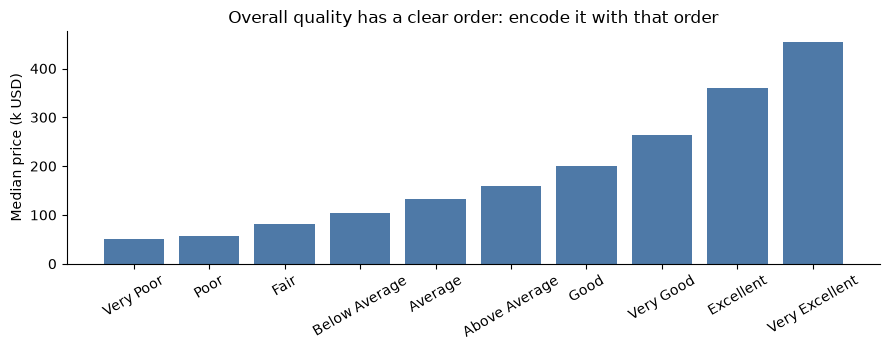

In [3]:
ames = datasets.ames()
ames = ames[ames["Gr_Liv_Area"] <= 4000]
alpha = OrdinalEncoder().fit_transform(ames[["Overall_Qual"]]).ravel()                       # alphabetical order
right = OrdinalEncoder(categories=[QUALITY]).fit_transform(ames[["Overall_Qual"]]).ravel()  # true order
print("correlation with log price - alphabetical codes:", round(np.corrcoef(alpha, np.log(ames["Sale_Price"]))[0, 1], 3))
print("correlation with log price - true order         :", round(np.corrcoef(right, np.log(ames["Sale_Price"]))[0, 1], 3))

fig, ax = plt.subplots(figsize=(9, 3.6))
med = ames.groupby("Overall_Qual")["Sale_Price"].median().reindex(QUALITY) / 1000
ax.bar(range(len(QUALITY)), med.values, color="#4E79A7")
ax.set(xticks=range(len(QUALITY)), xticklabels=[q.replace("_", " ") for q in QUALITY], ylabel="Median price (k USD)",
       title="Overall quality has a clear order: encode it with that order")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 3. Target Encoding without Leakage

Target encoding replaces each category with the mean target of that category. Computed on all rows, the encoded value of a row includes **its own target**, so the model sees a hint of the answer. Rare categories make this worse: a category with one row is encoded as exactly that row's target.

scikit-learn's `TargetEncoder` avoids this with **cross-fitting**: during `fit_transform`, each row is encoded with statistics from the other folds, and the means are shrunk towards the global mean for small categories.

In [4]:
rng = np.random.default_rng(RNG)
noise = pd.DataFrame({"random_id": rng.integers(0, 5000, len(adult)).astype(str)})     # a category with NO real information

naive = noise["random_id"].map(pd.Series(y.values, index=noise.index).groupby(noise["random_id"]).mean())
cv = StratifiedKFold(5, shuffle=True, random_state=RNG)
auc_naive = cross_val_score(LogisticRegression(), naive.to_frame(), y, cv=cv, scoring="roc_auc").mean()
auc_cross = cross_val_score(make_pipeline(TargetEncoder(cv=StratifiedKFold(5, shuffle=True, random_state=RNG)), LogisticRegression()), noise, y, cv=cv,
                            scoring="roc_auc").mean()
print(f"random id, naive target encoding (fit on all rows): ROC AUC {auc_naive:.3f}  <- fake signal")
print(f"random id, cross-fitted TargetEncoder in a pipeline : ROC AUC {auc_cross:.3f}  <- correct: no signal")

random id, naive target encoding (fit on all rows): ROC AUC 0.756  <- fake signal
random id, cross-fitted TargetEncoder in a pipeline : ROC AUC 0.496  <- correct: no signal


A column of random ids "predicts" income when it is target-encoded naively: pure leakage. Inside a pipeline with cross-fitting, it is correctly worthless (AUC ≈ 0.5).

## 4. Compare Encoders on Adult

In [5]:
def make_model(encoder, clf):
    pre = ColumnTransformer([("num", StandardScaler(), num), ("cat", encoder, cat)], sparse_threshold=0)   # dense output
    return make_pipeline(pre, clf)

def hash_cols(X):
    rows = X.astype(str).apply(lambda r: [f"{c}={v}" for c, v in r.items()], axis=1)
    return FeatureHasher(n_features=64, input_type="string").transform(rows).toarray()

encoders = {
    "one-hot": OneHotEncoder(handle_unknown="ignore", min_frequency=20),
    "ordinal (arbitrary order)": OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
    "target (cross-fitted)": TargetEncoder(cv=StratifiedKFold(5, shuffle=True, random_state=RNG)),
    "hashing (64 columns)": FunctionTransformer(hash_cols),
}
rows = []
for ename, enc in encoders.items():
    for cname, clf in [("logistic regression", LogisticRegression(max_iter=3000)),
                       ("gradient boosting", HistGradientBoostingClassifier(random_state=RNG))]:
        model = make_model(enc, clf)
        t = time.perf_counter()
        auc = cross_val_score(model, adult, y, cv=cv, scoring="roc_auc").mean()
        n_out = model.fit(adult.head(5000), y.head(5000))[0].transform(adult.head(5)).shape[1]
        rows.append({"encoder": ename, "model": cname, "ROC AUC": round(auc, 4), "features": n_out, "seconds": round(time.perf_counter() - t, 1)})
comparison = pd.DataFrame(rows)
comparison.pivot(index="encoder", columns="model", values="ROC AUC").join(comparison.groupby("encoder")["features"].first())

,gradient boosting,logistic regression,features
encoder,,,
hashing (64 columns),0.9252,0.8945,68
one-hot,0.9280,0.9066,69
ordinal (arbitrary order),0.9277,0.8163,12
target (cross-fitted),0.9273,0.9001,12


For the linear model, one-hot encoding is clearly better than arbitrary ordinal codes: a linear model cannot use an integer code whose order means nothing. The gradient-boosting model handles ordinal codes well, because trees can split the codes into any groups. Target encoding needs only one column per feature, which matters with high cardinality.

## 5. Unseen and Rare Categories in Production

New data can contain categories that the training data never had (a new occupation code, a new neighbourhood). Configure the encoder for it:

- `OneHotEncoder(handle_unknown="ignore")` → all zeros for unseen categories;
- `OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)`;
- `TargetEncoder` → the global mean for unseen categories;
- group rare categories (`min_frequency`, `max_categories`) so the model never relies on a handful of rows.

In [6]:
enc = OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=False).set_output(transform="pandas").fit(adult[["native_country"]])
new = pd.DataFrame({"native_country": ["United-States", "Atlantis", "Holand-Netherlands"]})
print("categories kept:", len(enc.categories_[0]), "| infrequent grouped:", len(enc.infrequent_categories_[0]))
out = enc.transform(new)
print(out.loc[:, (out != 0).any()].assign(input=new["native_country"].values))

categories kept: 42 | infrequent grouped: 33
   native_country_United-States  native_country_infrequent_sklearn  \
0                           1.0                                0.0   
1                           0.0                                0.0   
2                           0.0                                1.0   

                input  
0       United-States  
1            Atlantis  
2  Holand-Netherlands  


*Insight: Choose the encoder by model and cardinality: one-hot for linear models and few categories, ordinal with the true order for graded categories, cross-fitted target encoding or hashing for many categories. Always plan for rare and unseen categories, and fit encoders inside the pipeline.*

## Real-World Use Case or Analogy

Encoding is like **translating labels into a language the model reads**. One-hot is a checklist ("is it a nurse? a teacher? a driver?"), ordinal is a ranking ("grade 1 to 10"), target encoding is a reputation score ("people in this job earn X on average") — useful, but it must not be computed with the answer you are trying to predict.

Advertising and recommendation systems handle millions of category values (user ids, product ids) with hashing and learned embeddings (Lesson 15, M18); credit scoring often uses carefully regularised target encoding (weight of evidence, Lesson 06).